<h1 style="text-align: center;">02 Data Communication</h1>
<hr>


## **11. Acoustic Noise and Detection**

<div class="alert alert-light">

  **Name:** Stefan Sykes
  
  **Matriculation Number:** 11-250-693

</div>


### 11.1 Introduction

The previous notebook ([Acoustic Communication](02.10_Acoustic_Communication.ipynb)) introduced encoding information in audio signals. The tones were perfect because they were generated and read
back in the same process. A real microphone hears the ventilation, the
laptop fans, nearby conversations, the mains supply, and the
thermal noise of its own electronics. The signal that should be transmitted is added on top of
all of that.


This notebook examines how noise affects an audio signal and how the information can be recovered. 

Noise and interference concepts are explained in depth in the [Noise and Interference Notebook](02.6_Noise_and_Interference.ipynb).

The final activity takes the second step towards reading `secret_message.wav`: finding the frequencies it uses.


### 11.2 Record ambiant noise

Run the next cell and stay quiet while it records. Then look at the spectrum.

Sound levels are expressed in decibels (dB), a logarithmic scale that makes the very large range of sound levels more manageable and easier to work with.
Decibel values are always relative to some base value; for example, for sound this reference value is usually a pressure level of $20~\mu\text{Pa}$.
If this reference value is used, the sound pressure is expressed in dB SPL.


| Roughly      | Sound |
|--------------|---|
| 30 dB SPL    | A quiet bedroom at night |
| 40-50 dB SPL | A library, or a lecture hall before it fills |
| 60 dB SPL    | Normal conversation at one metre |
| 85 dB SPL    | A busy street; prolonged exposure starts to damage hearing |


The setup cell installs `sounddevice` into the notebook's Python environment for microphone recording. The first installation requires an internet connection. Allow microphone access if prompted by the operating system.

Set the variable `USE_LIVE_AUDIO` to `True` to use the device's microphone, or to `False` to use simulated noise.


In [1]:
# Install microphone support into the active notebook kernel.
%pip install --quiet sounddevice

print("Loading Matplotlib and the inline plotting backend...", flush=True)
%matplotlib inline

from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
print("Loading notebook widgets...", flush=True)
from ipywidgets import IntSlider, FloatSlider, FloatRangeSlider
from IPython.display import Audio, display

print("Locating the acoustic helpers...", flush=True)
for _root in (Path.cwd(), *Path.cwd().parents):
    ACOUSTIC_SUPPORT = _root / ".admin" / "acoustic_workshop"
    if (ACOUSTIC_SUPPORT / "acoustic.py").is_file():
        break
else:
    raise FileNotFoundError("Start Jupyter from inside the MobileComputing repository.")

if str(ACOUSTIC_SUPPORT) not in sys.path:
    sys.path.insert(0, str(ACOUSTIC_SUPPORT))

print("Loading acoustic helpers...", flush=True)
import acoustic as ac

ACOUSTIC_ASSETS = ACOUSTIC_SUPPORT / "assets"

USE_LIVE_AUDIO = True     # set False to use simulated noise instead
rate = ac.SAMPLE_RATE
WIDE = {"description_width": "initial"}

print("Setup ready. Audio mode: OFFLINE (simulated noise)."
      if not USE_LIVE_AUDIO else "Setup ready. Audio mode: LIVE (microphone).",
      flush=True)
print("Run the next code cell to generate the background waveform and spectrum.",
      flush=True)


Note: you may need to restart the kernel to use updated packages.
Loading Matplotlib and the inline plotting backend...



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Loading notebook widgets...
Locating the acoustic helpers...
Loading acoustic helpers...
Setup ready. Audio mode: LIVE (microphone).
Run the next code cell to generate the background waveform and spectrum.


Run the cell below to record the noise level detected by the device.
The spectrum below uses relative dB, not dB SPL. Since the recorded digital amplitudes are compared against an arbitrary reference value, negative dB values are normal and simply indicate magnitudes below that reference.

Recording for 5.0 s ...
Recording complete.
Mode: LIVE - this is your own speaker, room, and microphone.
    0-500   Hz   mean level   -84.9 dB
  500-1500  Hz   mean level   -87.3 dB
 1500-4000  Hz   mean level   -93.8 dB
 4000-8000  Hz   mean level   -97.1 dB


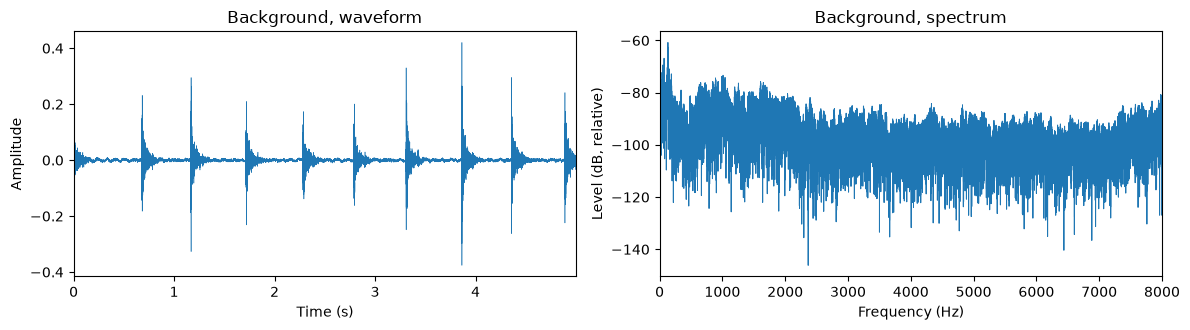

In [2]:
room, mode = ac.record(5.0, rate, offline=not USE_LIVE_AUDIO)
ac.describe_mode(mode)

frequencies, magnitude = ac.spectrum(room, rate)
band = frequencies <= 8000
decibels = 20 * np.log10(magnitude + 1e-12)

room_figure, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].plot(np.arange(len(room)) / rate, room, linewidth=0.4)
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude")
axes[0].set_title("Background, waveform")
axes[0].margins(x=0)
axes[1].plot(frequencies[band], decibels[band], linewidth=0.7)
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Level (dB, relative)")
axes[1].set_title("Background, spectrum")
axes[1].margins(x=0)
room_figure.tight_layout()

for low, high in [(0, 500), (500, 1500), (1500, 4000), (4000, 8000)]:
    piece = (frequencies >= low) & (frequencies < high)
    print(f"{low:>5}-{high:<5} Hz   mean level {20*np.log10(magnitude[piece].mean() + 1e-12):7.1f} dB")


The measured spectrum is almost certainly not flat. Room background is
strongly tilted towards low frequencies, because ventilation, traffic, and
footsteps live down there, and because low frequencies travel through walls
and around obstacles far better than high ones. On top of the tilt, a spike may appear at 50 Hz and its harmonics, which is the European mains supply
leaking into the analogue path.

>  **White noise** is frequently used in simulation, it is noise with equal average power in every Hertz of the
spectrum: a flat line. It is the standard model, and the *N* in AWGN.

> **Try it.** Rerun the cell, and speak while it
> records. Which frequencies does the recorded voice occupy? 
> Most of it lands between about 300 Hz and 3 kHz, which is exactly the band a telephone keeps and
> everything else throws away.


Watch the spectrum live on this webapp https://waver.ggerganov.com/

### 11.3 Received signal power

The quantity that decides whether a link works is not the signal level. It is
the **signal-to-noise ratio (SNR)**, the ratio of wanted power to unwanted power:

$$\mathrm{SNR_{dB}} = 10\log_{10}\frac{P_\text{signal}}{P_\text{noise}}$$

At 20 dB the signal has a hundred times the power of the noise. At 0 dB they
are equal. At $-10$ dB the noise is ten times stronger.

Lower the slider and identify where the tones become inaudible. Watch the two
spectral peaks at the same time: they stay visible long after the tones stop
being audible.


In [3]:
binary_tones = np.array([600.0, 1200.0])
signal_bits = ac.text_to_bits("SIGNAL")
clean = ac.modulate(signal_bits, binary_tones, 60, rate)

def make_noisy(snr_db):
    return ac.add_noise(clean, rate, snr_db=float(snr_db), seed=4)

def make_snr_figure(snr_db):
    noisy = make_noisy(snr_db)
    f, m = ac.spectrum(noisy, rate)
    keep = f <= 3000
    figure, axes = plt.subplots(1, 2, figsize=(12, 3.4))
    axes[0].plot(np.arange(len(noisy)) / rate, noisy, linewidth=0.4)
    axes[0].set_xlabel("Time (s)")
    axes[0].set_ylabel("Amplitude")
    axes[0].set_title("Waveform")
    axes[0].margins(x=0)
    axes[1].plot(f[keep], 20 * np.log10(m[keep] + 1e-12), linewidth=0.7)
    for tone in binary_tones:
        axes[1].axvline(tone, color="tab:red", linestyle="--", linewidth=0.9)
    axes[1].set_xlabel("Frequency (Hz)")
    axes[1].set_ylabel("Level (dB)")
    axes[1].set_title("Spectrum, with the two tones marked")
    axes[1].margins(x=0)
    figure.suptitle(f"'SIGNAL' as binary FSK at SNR {snr_db} dB")
    figure.tight_layout()
    return figure


IntSlider(value=15, continuous_update=False, description='SNR (dB)', max=30, min=-20, style=SliderStyle(descri…

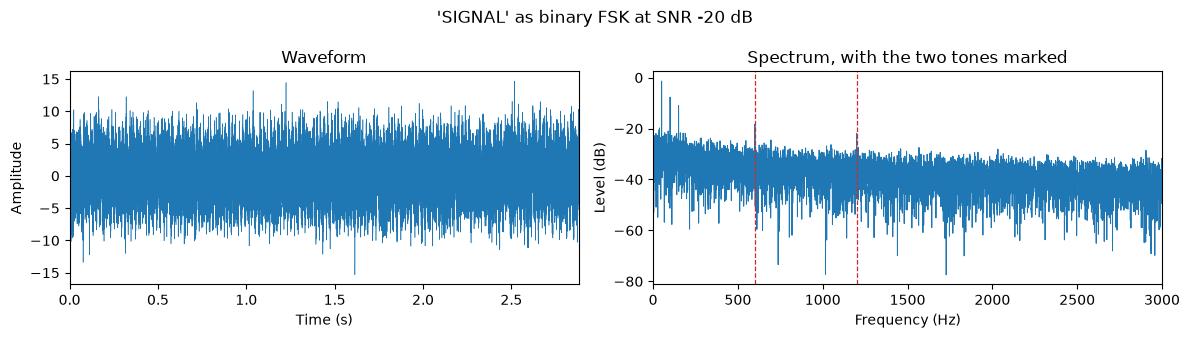

In [12]:
snr_slider = IntSlider(min=-20, max=30, step=1, value=15,
                       description="SNR (dB)",
                       continuous_update=False, style=WIDE)
display(snr_slider)

snr_figure = make_snr_figure(snr_slider.value)
snr_handle = display(snr_figure, display_id=True)
plt.close(snr_figure)
snr_audio = display(Audio(make_noisy(snr_slider.value), rate=rate, normalize=True), display_id=True)

def update_snr_plot(change=None):
    snr_figure = make_snr_figure(snr_slider.value)
    snr_handle.update(snr_figure)
    plt.close(snr_figure)
    snr_audio.update(Audio(make_noisy(snr_slider.value), rate=rate, normalize=True))

snr_slider.observe(update_snr_plot, names="value")


Notice that the two tones stay visible as peaks in the spectrum long after
they have become hard to hear. The receiver detects tones differently from human hearing.
It knows exactly which two frequencies to look at, and it can ignore
everything else.

> **A real system cannot simply increase transmit power.** Transmit power is capped
> by regulation and by hardware, and in radio it is quoted in **dBm**, decibels
> relative to one milliwatt. Wi-Fi indoors is typically limited to about 20 dBm, which is
> 100 mW. When signal power cannot be raised, a link that is failing has to be
> fixed on the transmitter side: send more slowly, or use fewer distinct states.


### 11.4 Decoding the signal

During one symbol interval, the receiver gets the transmitted tone plus noise:

$$y_k[m] = x_k[m] + n_k[m],$$

The receiver turns these samples into a few scores, then chooses the symbol
with the best score. This is the same basic idea used by
[BPSK and QAM](02.4_Digital_Modulation.ipynb):

| Modulation | Scores | Decision |
|---|---|---|
| BPSK | one signed score | Is it positive or negative? |
| QAM | an $I$ score and a $Q$ score | Which constellation point is closest? |
| Binary FSK | one score for 600 Hz and one for 1200 Hz | Which score is larger? |

For binary FSK, bit 0 uses 600 Hz and bit 1 uses 1200 Hz. For each candidate
frequency $f_i$, the receiver asks: **how well do the samples match this
tone?**

It first creates two clean reference waves at $f_i$, one cosine and one sine,
and multiplies the received samples by each reference:

$$
\begin{aligned}
C_i[k] &= \frac{1}{N}\sum_{m=0}^{N-1}y_k[m]\cos(2\pi f_i m/f_s),\\
S_i[k] &= \frac{1}{N}\sum_{m=0}^{N-1}y_k[m]\sin(2\pi f_i m/f_s).
\end{aligned}
$$

Here, $k$ identifies the symbol, $i\in\{0,1\}$ chooses the candidate tone,
$m$ counts its samples, $m/f_s$ is the time of sample $m$, and $N$ is the
number of samples used. The multiplication is the important step:

- With a matching frequency, at least one product contains a steady part.
  Averaging keeps that part, so the score is large.
- With the wrong frequency, the products keep swinging above and below zero.
  Averaging makes them mostly cancel, so the score is small.

This **multiply-and-average** operation is called correlation.

The detector tests with both cosine and sine because the received tone may arrive with
any phase. Combining the two results gives a phase-independent score:

$$z_i[k]=\sqrt{C_i[k]^2+S_i[k]^2}.$$

The complex exponential is simply a shorter way to write the same two
multiplications. Here, $j=\sqrt{-1}$. Euler's formula gives
$e^{-j\theta}=\cos(\theta)-j\sin(\theta)$, so

$$
z_i[k] = \left|\frac{1}{N}\sum_{m=0}^{N-1}
y_k[m]e^{-j2\pi f_i m/f_s}\right|.
$$

The absolute-value bars combine the cosine and sine results and discard the
unknown phase. This is why the method is called **non-coherent detection**.

The decision is a comparison, not an absolute threshold:

$$
\hat b[k] =
\begin{cases}
0, & z_0[k] \ge z_1[k],\\
1, & z_1[k] > z_0[k].
\end{cases}
$$

The left plot is the FSK equivalent of a constellation diagram. The crosses
mark the clean reference states: 0 lies near the horizontal axis and 1 near
the vertical axis. Points are coloured by the bit that was transmitted. Noise
spreads each cloud; a bit error occurs when a point crosses the dashed
decision boundary $z_0=z_1$. The right plot shows the same two scores for each
symbol in `SIGNAL`; the circle marks the larger score selected by the decoder.
Move the SNR slider down and watch the points cross the boundary and the
decoded text fall apart.


In [5]:
detector_ms = 60
detector_wave = ac.modulate(signal_bits, binary_tones, detector_ms, rate)
clean_scores = ac.tone_energies(detector_wave, rate, binary_tones, 0,
                                len(signal_bits), detector_ms)
ideal_scores = np.vstack([
    clean_scores[signal_bits == bit].mean(axis=0) for bit in (0, 1)
])

# Keep both axes and the colour scale fixed while the slider moves.
# Otherwise autoscaling would make the noise clouds appear not to grow.
noisiest = ac.add_noise(detector_wave, rate, snr_db=-20, seed=8)
noisiest_scores = ac.tone_energies(noisiest, rate, binary_tones, 0,
                                    len(signal_bits), detector_ms)
detect_axis_max = 1.08 * noisiest_scores.max()
detect_axis_pad = 0.03 * detect_axis_max

def make_detect_figure(snr_db):
    noisy = ac.add_noise(detector_wave, rate, snr_db=float(snr_db), seed=8)
    scores = ac.tone_energies(noisy, rate, binary_tones, 0,
                              len(signal_bits), detector_ms)
    decided = ac.demodulate(scores)
    error_mask = signal_bits != decided
    error_count = int(error_mask.sum())
    shown = ac.readable(ac.bits_to_bytes(decided))

    figure, (decision_axis, symbol_axis) = plt.subplots(
        1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 1.45]}
    )

    boundary = np.array([0.0, detect_axis_max])
    decision_axis.fill_between(boundary, 0, boundary, color="tab:blue",
                               alpha=0.07)
    decision_axis.fill_between(boundary, boundary, detect_axis_max,
                               color="tab:orange", alpha=0.07)
    decision_axis.plot(boundary, boundary, color="0.35", linestyle="--",
                       linewidth=1.1, label=r"decision boundary $z_0=z_1$")

    for bit, color in [(0, "tab:blue"), (1, "tab:orange")]:
        transmitted = signal_bits == bit
        decision_axis.scatter(scores[transmitted, 0], scores[transmitted, 1],
                              s=30, color=color, alpha=0.75,
                              label=f"transmitted {bit}")
        decision_axis.scatter(ideal_scores[bit, 0], ideal_scores[bit, 1],
                              s=120, color=color, marker="X",
                              edgecolor="white", linewidth=0.8,
                              label=f"clean reference {bit}")

    decision_axis.scatter(scores[error_mask, 0], scores[error_mask, 1],
                          s=90, facecolors="none", edgecolors="tab:red",
                          linewidth=1.8, label="bit error")
    decision_axis.text(0.70 * detect_axis_max, 0.10 * detect_axis_max,
                       "decode 0", color="tab:blue", ha="center")
    decision_axis.text(0.10 * detect_axis_max, 0.76 * detect_axis_max,
                       "decode 1", color="tab:orange", ha="center")
    decision_axis.set(
        xlim=(-detect_axis_pad, detect_axis_max),
        ylim=(-detect_axis_pad, detect_axis_max),
        xlabel="600 Hz correlation magnitude, $z_0$",
        ylabel="1200 Hz correlation magnitude, $z_1$",
        title="FSK decision space",
    )
    decision_axis.set_aspect("equal", adjustable="box")
    decision_axis.grid(alpha=0.2)
    decision_axis.legend(fontsize=7, loc="upper right")

    symbol_numbers = np.arange(len(signal_bits))
    score_image = symbol_axis.imshow(
        scores.T, origin="lower", aspect="auto", cmap="magma",
        vmin=0, vmax=detect_axis_max,
        extent=(-0.5, len(signal_bits) - 0.5, -0.5, 1.5),
    )
    symbol_axis.scatter(symbol_numbers, decided, s=22, facecolors="none",
                        edgecolors="cyan", linewidth=1.0,
                        label="selected score")
    symbol_axis.scatter(symbol_numbers[error_mask], decided[error_mask],
                        s=35, marker="x", color="tab:red",
                        linewidth=1.4, label="wrong decision")
    symbol_axis.set(
        xlabel="Symbol number", ylabel="Candidate tone",
        yticks=[0, 1], yticklabels=["bit 0: 600 Hz", "bit 1: 1200 Hz"],
        title="Two receiver scores per symbol",
    )
    symbol_axis.legend(fontsize=8, loc="upper right")
    figure.colorbar(score_image, ax=symbol_axis, pad=0.02,
                    label="Correlation magnitude")

    figure.suptitle(
        f"SNR {snr_db} dB   {error_count} bit errors of {len(signal_bits)}"
        f"   ->   {shown!r}"
    )
    figure.tight_layout()
    return figure


IntSlider(value=3, continuous_update=False, description='SNR (dB)', max=20, min=-20, style=SliderStyle(descrip…

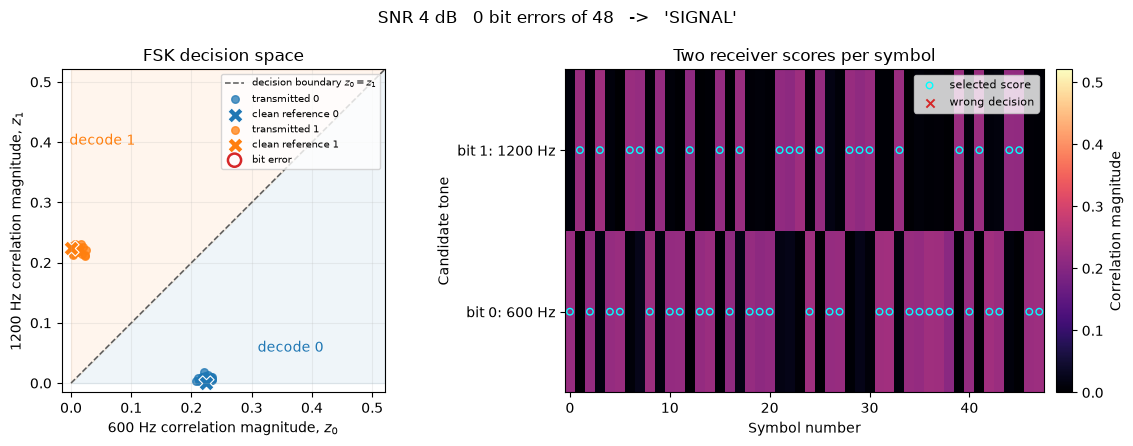

In [6]:
detect_slider = IntSlider(min=-20, max=20, step=1, value=3,
                          description="SNR (dB)",
                          continuous_update=False, style=WIDE)
display(detect_slider)

detect_figure = make_detect_figure(detect_slider.value)
detect_handle = display(detect_figure, display_id=True)
plt.close(detect_figure)

def update_detect_plot(change=None):
    detect_figure = make_detect_figure(detect_slider.value)
    detect_handle.update(detect_figure)
    plt.close(detect_figure)

detect_slider.observe(update_detect_plot, names="value")


#### 11.4.1 From decisions to a BER curve

One decoded message contains too few bits to measure reliability well. The
**bit error rate (BER)** is the fraction of transmitted bits that the receiver
decides incorrectly.

For every SNR value below, the simulation transmits the same 1200 random bits using the
60 ms FSK symbols from the decoder above. At very low SNR, the two decision
clouds overlap and the BER approaches 0.5: the receiver is almost guessing.
As SNR rises, the clouds separate and the BER falls towards zero. Downward
triangles mark SNR values where no errors were observed; they are drawn at a
small floor because zero cannot appear on a logarithmic axis.


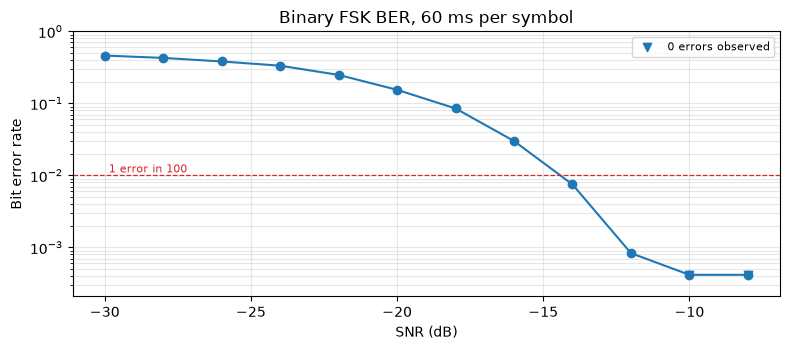

In [7]:
# Use the same bits and noise realization at every SNR for a fair comparison.
trial_bits = np.random.default_rng(0).integers(0, 2, 1200).astype(np.uint8)
snr_values = np.arange(-30, -7, 2.0)

def measure_ber(symbol_ms, tones_hz, test_snr_values=snr_values,
                test_bits=trial_bits, batch_bits=None):
    bits_per_symbol = ac.bits_per_symbol(len(tones_hz))
    batch_bits = batch_bits or len(test_bits)
    error_counts = np.zeros(len(test_snr_values), dtype=int)

    for batch_index, start in enumerate(range(0, len(test_bits), batch_bits)):
        bits = test_bits[start:start + batch_bits]
        wave = ac.modulate(bits, tones_hz, symbol_ms, rate)
        symbol_count = len(bits) // bits_per_symbol
        for snr_index, snr_db in enumerate(test_snr_values):
            received = ac.add_noise(
                wave, rate, snr_db=float(snr_db), seed=1 + batch_index
            )
            scores = ac.tone_energies(received, rate, tones_hz, 0,
                                      symbol_count, symbol_ms)
            decoded = ac.demodulate(scores)
            error_counts[snr_index] += np.count_nonzero(decoded != bits)
    return error_counts / len(test_bits)

ber_at_60_ms = measure_ber(detector_ms, binary_tones)
ber_floor = 0.5 / len(trial_bits)
plotted_ber = np.maximum(ber_at_60_ms, ber_floor)

ber_snr_figure, ber_snr_axis = plt.subplots(figsize=(8, 3.6))
ber_snr_axis.semilogy(snr_values, plotted_ber, marker="o")
ber_snr_axis.axhline(0.01, color="tab:red", linestyle="--", linewidth=0.9)
ber_snr_axis.text(snr_values[0], 0.011, " 1 error in 100",
                  color="tab:red", fontsize=8)
zero_errors = ber_at_60_ms == 0
ber_snr_axis.scatter(snr_values[zero_errors], plotted_ber[zero_errors],
                     marker="v", color="tab:blue",
                     label="0 errors observed")
ber_snr_axis.set(
    xlabel="SNR (dB)", ylabel="Bit error rate",
    ylim=(ber_floor / 2, 1),
    title=f"Binary FSK BER, {detector_ms} ms per symbol",
)
ber_snr_axis.grid(True, which="both", alpha=0.3)
ber_snr_axis.legend(fontsize=8)
ber_snr_figure.tight_layout()


### 11.5 More tones in the same bandwidth

Binary FSK gives the transmitter two choices: send the low tone for bit 0 or
the high tone for bit 1. Because there are two choices, one symbol carries
one bit.

Higher-order FSK offers more choices while still transmitting only **one tone at a
time**:

- **4-FSK** chooses one of four tones, so one symbol carries two bits.
- **8-FSK** chooses one of eight tones, so one symbol carries three bits.

Each point now represents **6000 transmitted bits**, which makes small BER
differences visible without the staircase caused by counting only one or two
errors. For a fair comparison, all three schemes use 20 ms symbols and the same
available frequency band from 600 to 900 Hz. Guard space is left at both
edges, so every tone center lies between 675 and 825 Hz. Adding more tones
therefore packs them closer together. The receiver must also compare more
scores and choose the largest one. Noise is then more likely to make the
wrong score win.

The left plot shows the candidate tones inside the fixed band. The right plot
shows the BER-versus-SNR curves. This illustrates the **modulation-order**
part of a **modulation and coding scheme (MCS)**: more bits per symbol increase the data rate, but require a
cleaner channel. Channel coding is not changed in this experiment.


Text(0.5, 0.98, 'Fixed bandwidth: data rate versus reliability')

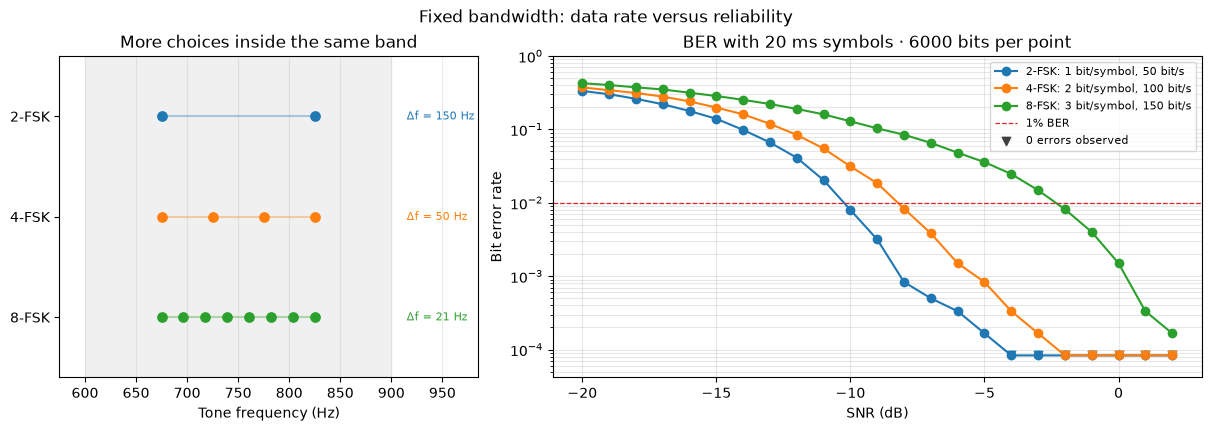

In [8]:
fixed_band_hz = (600.0, 900.0)
tone_center_range_hz = (675.0, 825.0)  # Guard space inside the band edges.
comparison_symbol_ms = 20
mfsk_snr_values = np.arange(-20, 3, 1.0)
mfsk_trial_bits = np.random.default_rng(0).integers(0, 2, 6000).astype(np.uint8)
mfsk_ber_floor = 0.5 / len(mfsk_trial_bits)
mfsk_orders = (2, 4, 8)
mfsk_colors = ("tab:blue", "tab:orange", "tab:green")

mfsk_figure, (tone_axis, ber_axis) = plt.subplots(
    1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.55]},
    constrained_layout=True,
)

tone_axis.axvspan(*fixed_band_hz, color="0.94", label="available band")
for row, order, color in zip((2, 1, 0), mfsk_orders, mfsk_colors):
    tones_hz = np.linspace(*tone_center_range_hz, order)
    bits_per_symbol = ac.bits_per_symbol(order)
    bit_rate = 1000 * bits_per_symbol / comparison_symbol_ms

    tone_spacing_hz = tones_hz[1] - tones_hz[0]
    tone_axis.hlines(row, *tone_center_range_hz, color=color, alpha=0.35)
    tone_axis.scatter(tones_hz, np.full(order, row), color=color, s=45)

    error_rate = measure_ber(
        comparison_symbol_ms, tones_hz, mfsk_snr_values, mfsk_trial_bits,
        batch_bits=1200,
    )
    plotted_error_rate = np.maximum(error_rate, mfsk_ber_floor)
    ber_axis.semilogy(
        mfsk_snr_values, plotted_error_rate, marker="o",
        color=color,
        label=f"{order}-FSK: {bits_per_symbol} bit/symbol, {bit_rate:.0f} bit/s",
    )
    zero_errors = error_rate == 0
    ber_axis.scatter(mfsk_snr_values[zero_errors],
                     plotted_error_rate[zero_errors], marker="v",
                     color=color, zorder=3)
    tone_axis.text(915, row, f"Δf = {tone_spacing_hz:.0f} Hz",
                   va="center", color=color, fontsize=8)

tone_axis.set(
    xlim=(575, 985), ylim=(-0.6, 2.6), xlabel="Tone frequency (Hz)",
    yticks=(2, 1, 0), yticklabels=("2-FSK", "4-FSK", "8-FSK"),
    title="More choices inside the same band",
)
tone_axis.grid(axis="x", alpha=0.25)

ber_axis.axhline(0.01, color="tab:red", linestyle="--",
                 linewidth=0.9, label="1% BER")
ber_axis.scatter([], [], marker="v", color="0.25",
                 label="0 errors observed")
ber_axis.set(
    xlabel="SNR (dB)", ylabel="Bit error rate",
    ylim=(mfsk_ber_floor / 2, 1),
    title=f"BER with {comparison_symbol_ms} ms symbols · 6000 bits per point",
)
ber_axis.grid(True, which="both", alpha=0.3)
ber_axis.legend(fontsize=8)
mfsk_figure.suptitle("Fixed bandwidth: data rate versus reliability")


Read the BER plot at one SNR and compare the three curves. The 2-FSK receiver
usually makes the fewest mistakes. The 8-FSK receiver sends three times as
many bits per symbol, but its tones are more tightly packed and its BER is
higher. At sufficiently high SNR, all three schemes become reliable.

This is the central MCS trade-off: use a higher modulation order when the
channel is clean, and fall back to a lower order when it is noisy. A complete
MCS also changes the channel-coding rate.


### 11.6 The Secret Message, Second Look

Notebook 02.10 showed that `secret_message.wav` contains two short bursts
with a long block between them. Now find out what frequencies that block uses.

**Take the spectrum of a window inside the block, not of the whole file.** A
spectrum of the whole recording averages the bursts, the block, and the silence
together, and the tones of interest disappear into the mixture. Drag the window
until the peaks are as sharp as possible. The exercise (11.7) uses this spectrum
to extract the exact tone frequencies.


In [9]:
secret, secret_rate = ac.load_wav(ACOUSTIC_ASSETS / "secret_message.wav")
secret_duration = len(secret) / secret_rate

def make_spectrum_figure(window):
    return ac.plot_spectrum(
        secret, secret_rate, seconds=tuple(window), max_hz=3600,
        title=f"secret_message.wav   {window[0]:.2f} s to {window[1]:.2f} s")


FloatRangeSlider(value=(2.0, 6.0), continuous_update=False, description='Window (s)', max=8.41, step=0.05, sty…

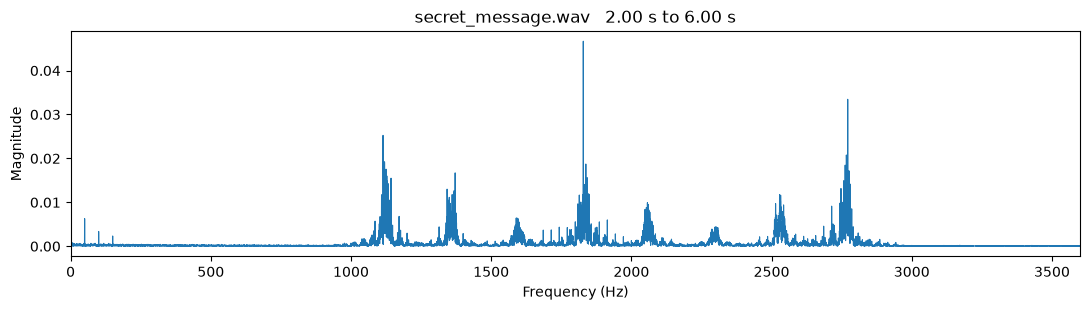

In [10]:
window_slider = FloatRangeSlider(min=0.0, max=round(secret_duration, 2), step=0.05,
                                value=[2.0, 6.0], readout_format=".2f",
                                description="Window (s)", continuous_update=False, style=WIDE)
display(window_slider)

spectrum_figure = make_spectrum_figure(window_slider.value)
spectrum_handle = display(spectrum_figure, display_id=True)
plt.close(spectrum_figure)

def update_spectrum_plot(change=None):
    spectrum_figure = make_spectrum_figure(window_slider.value)
    spectrum_handle.update(spectrum_figure)
    plt.close(spectrum_figure)

window_slider.observe(update_spectrum_plot, names="value")


Evenly spaced peaks are the signature of FSK: each symbol is one tone chosen
from a fixed ladder. If the block uses $N$ tones, one symbol carries
$\log_2 N$ bits.

Use the spacing as a check on the selected window and peak count. Consecutive
tones should be almost equally spaced. If one gap is roughly double the
others, a tone was missed, usually because the window is too short for the
transform to resolve them. If the spacing is large and irregular, the window
is outside the block.

This spectral analysis also provides a way to discover unknown tone frequencies
before decoding. The receiver computes an FFT spectrum of a window containing
data and identifies its strongest peaks as candidate FSK tones. Comparing
several windows helps distinguish recurring tone frequencies from noise and
reveals tones that may be absent from an individual window. The detected
frequencies can then serve as the reference frequencies for the tone detector
in Section 11.4. The mapping from tones to bit patterns must still be known
or established separately.


---

### 11.7 Hands-On Exercise



<div class="alert alert-block alert-info">Fill in the responses and save this notebook. See the <a href="../../03_Assignments/Submission-Guidelines.md">submission guidelines</a> for how to submit your work.</div>

State whether each result is live or offline, and report measured values rather than expected values.


**Is the recorded background close to white noise? Cite one specific feature of the measured spectrum that supports the answer, with the frequency range it occurs in.**

No, it is not close to white noise. White noise would have the same level at all frequencies, a flat line. My measured level falls steadily from low to high frequencies:

| Frequency range | Mean level |
|---|---|
| 0 to 500 Hz | $-84.9$ dB |
| 500 to 1500 Hz | $-87.3$ dB |
| 1500 to 4000 Hz | $-93.8$ dB |
| 4000 to 8000 Hz | $-97.1$ dB |

The noise is about 12 dB stronger at 0 to 500 Hz than at 4000 to 8000 Hz. Room noise is concentrated at low frequencies, for example from ventilation and traffic.

**Using the SNR slider in 11.3, report the SNR at which the tones become inaudible to the listener, and the SNR at which the two peaks stop being visible in the spectrum. Explain the gap between the two numbers.**

- The tones become inaudible at about −10 dB.
- The peaks are still faintly visible at −20 dB, the lowest setting of the slider. They only barely stick out above the noise.

The peaks stay visible at least 10 dB longer than the tones stay audible. My ear hears all frequencies mixed together, so the noise covers the tones. The spectrum splits the sound into single frequencies. The noise is spread over all frequencies, but each tone's energy sits at one exact frequency, so it still sticks out as a peak.

**For a maximum acceptable BER of 0.01, use the graph in 11.5 to find the lowest SNR at which 2-FSK, 4-FSK, and 8-FSK each meet this requirement.**

| Scheme | Tone spacing | Bit rate | Lowest SNR with BER ≤ 0.01 |
|---|---|---|---|
| 2-FSK | 150 Hz | 50 bit/s | about **−10 dB** |
| 4-FSK | 50 Hz | 100 bit/s | about **−8 dB** |
| 8-FSK | 21 Hz | 150 bit/s | about **−2 dB** |

The more tones, the higher the SNR needed. All schemes use the same frequency band, so more tones means they are packed closer together and are easier to confuse. 8-FSK is 3 times faster than 2-FSK, but needs about 8 dB more SNR.

**In 11.4, the receiver decodes BFSK by measuring the energy at two reference frequencies and selecting the strongest one. How would the detector work for 4-FSK and 8-FSK? Explain how many frequencies it must test and how it selects the transmitted symbol.**

The detector works the same way as for BFSK, just with more frequencies. BFSK has 2 tones (600 Hz and 1200 Hz), so the receiver tests 2 frequencies. In general, it must test every possible tone:

- 4-FSK has 4 tones, so the receiver tests 4 frequencies and gets 4 scores per symbol.
- 8-FSK has 8 tones, so the receiver tests 8 frequencies and gets 8 scores per symbol.

For each symbol, it picks the frequency with the largest score. That is the tone that was most likely sent. It then looks up which bits belong to this tone. The number of bits per tone is $\log_2 M$, where $M$ is the number of tones:

- 4-FSK: $\log_2 4 = 2$ bits, because $2^2 = 4$
- 8-FSK: $\log_2 8 = 3$ bits, because $2^3 = 8$

**The detector assumes that the possible tone frequencies are known. If they are not known, how could the receiver discover them from the recorded signal before decoding it?**

The receiver can compute the spectrum (FFT) of a part of the recording that contains data, not the whole file. Each tone that is used appears as a peak, so the strongest peaks show the tone frequencies. To be sure, it can check several parts of the recording. Real tones appear again and again, while random noise peaks do not. The tones should also be evenly spaced. If one gap is about twice as large as the others, a tone was missed. The receiver then uses these frequencies as reference frequencies for the detector. It still needs to know which bits belong to which tone.

**Explain why eight tones carry three bits per symbol rather than eight, and what would be needed to carry four.**

Only one tone is sent at a time, so each symbol is one choice out of 8 possible tones. With 3 bits, we can make exactly $2^3 = 8$ different combinations (000, 001, 010, 011, 100, 101, 110, 111), one for each tone. So 8 tones carry $\log_2 8 = 3$ bits per symbol, not 8. To carry 4 bits per symbol, we need $2^4 = 16$ different tones.

**OPTIONAL: Have all tasks in this notebook been read and understood? Are there any shortcomings, missing parts, or sections that should be improved?**

Please help the teaching team improve the notebook by identifying any unclear tasks or explanations and suggesting improvements.

(answer here)
